# Tutorial 4: The evidence around one paper

A search finds papers by their words. An **evidence neighborhood** starts from one key paper and follows PubMed's links instead: papers PubMed rates as **similar**, papers that **cite** it, and the papers it **cites**. Each one is flagged as a review, retracted or NIH-funded. It is the programmatic counterpart of NLM's [Linked Discoveries](https://linkeddiscoveries.ncbi.nlm.nih.gov/) web tool.

This tutorial maps the neighborhood of a 2019 review on the gut microbiota in frailty and sarcopenia, then uses a famously retracted paper to show retraction screening. It takes about a minute.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tutorial_utils as tu

tu.setup()
tu.style()

from pubmed_stream import get_neighborhood, save_neighborhood

## 1. Fetch a neighborhood

`max_per_relation` caps how many articles of each relation are fetched in detail. The totals and flag counts always cover **every** linked article, even beyond the cap.

In [2]:
SEED = "31319564"   # Gut Microbiota, Muscle Mass and Function in Aging (Nutrients, 2019)
hood = get_neighborhood(SEED, max_per_relation=50)

print(f"Seed: {hood.seed.title} ({hood.seed.year})")
summary = pd.DataFrame([
    {"relation": name, "fetched": len(getattr(hood, name)), "total": hood.totals[name], **hood.flag_counts[name]}
    for name in ["similar", "cited_by", "references"]
]).set_index("relation")
summary

Seed: Gut Microbiota, Muscle Mass and Function in Aging: A Focus on Physical Frailty and Sarcopenia. (2019)


,fetched,total,reviews,retracted,nih_funded,in_pmc
relation,,,,,,
similar,50,384,206,1,47,238
cited_by,50,239,125,0,13,230
references,50,139,58,0,34,76


## 2. How big is it, and what kind of evidence?

The left panel shows how much of each relation was fetched in detail. The right panel shows the flags across **all** linked articles. Reviews dominate the papers citing a review, which is typical: reviews cite reviews.

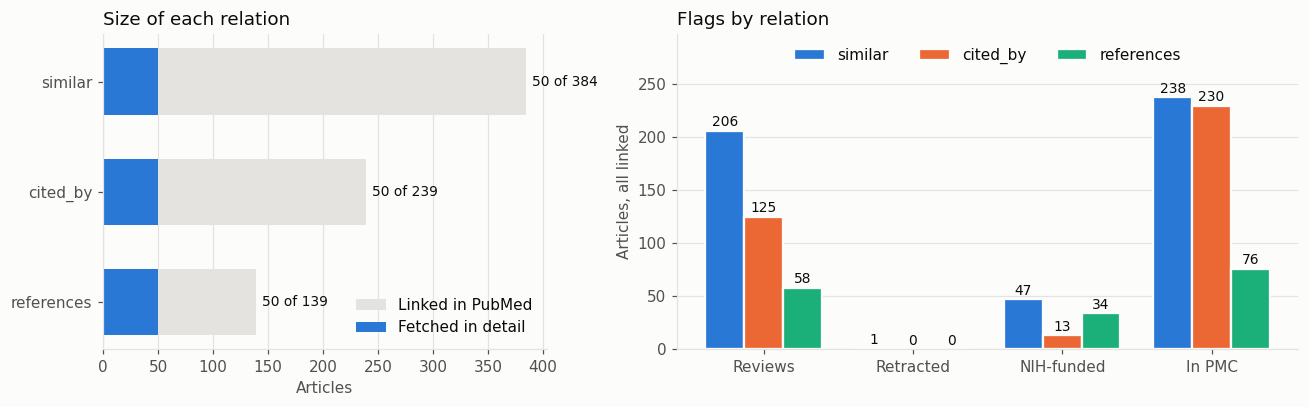

In [3]:
relations = ["similar", "cited_by", "references"]
colours = {"similar": tu.BLUE, "cited_by": tu.ORANGE, "references": tu.AQUA}
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})

y = np.arange(len(relations))
left.barh(y, [hood.totals[r] for r in relations], color=tu.GRID, height=0.6, label="Linked in PubMed")
bars = left.barh(y, [len(getattr(hood, r)) for r in relations], color=tu.BLUE, height=0.6, label="Fetched in detail")
for i, r in enumerate(relations):
    left.annotate(f"{len(getattr(hood, r))} of {hood.totals[r]}", (hood.totals[r], i), xytext=(4, 0),
                  textcoords="offset points", va="center", fontsize=9)
left.set_yticks(y, relations)
left.invert_yaxis()
tu.gridlines(left, "x")
left.set_xlabel("Articles")
left.legend(loc="lower right")
left.set_title("Size of each relation")

flags = ["reviews", "retracted", "nih_funded", "in_pmc"]
x = np.arange(len(flags))
width = 0.26
for i, r in enumerate(relations):
    bars = right.bar(x + (i - 1) * width, [hood.flag_counts[r][f] for f in flags], width,
                     color=colours[r], edgecolor=tu.SURFACE, lw=1.5, label=r)
    tu.bar_labels(right, bars, zero=True)
right.set_xticks(x, ["Reviews", "Retracted", "NIH-funded", "In PMC"])
tu.gridlines(right)
right.set_ylim(0, max(max(c.values()) for c in hood.flag_counts.values()) * 1.25)
right.set_ylabel("Articles, all linked")
right.legend(loc="upper center", ncol=3)
right.set_title("Flags by relation")
plt.tight_layout()
plt.show()

## 3. When was it published?

References look back from the seed, and citing papers look forward. Together they place the seed in time: here, the field kept citing a 2019 review heavily through 2026.

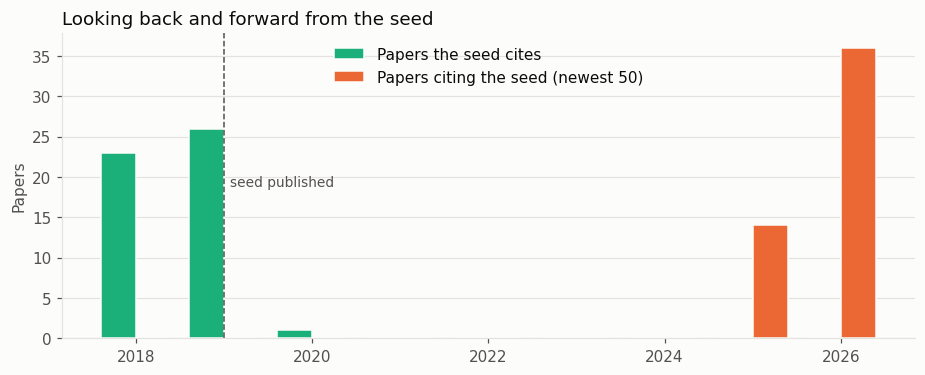

In [4]:
def years(articles):
    return pd.Series([int(a.year) for a in articles if a.year and a.year.isdigit()]).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 3.6))
cites, cited = years(hood.references), years(hood.cited_by)
span = range(min(cites.index.min(), cited.index.min()), max(cites.index.max(), cited.index.max()) + 1)
cites, cited = cites.reindex(span, fill_value=0), cited.reindex(span, fill_value=0)
ax.bar(np.array(span) - 0.2, cites.values, 0.4, color=tu.AQUA, edgecolor=tu.SURFACE, label="Papers the seed cites")
ax.bar(np.array(span) + 0.2, cited.values, 0.4, color=tu.ORANGE, edgecolor=tu.SURFACE, label=f"Papers citing the seed (newest {len(hood.cited_by)})")
ax.axvline(int(hood.seed.year), color=tu.INK_2, lw=1, ls="--")
ax.annotate("seed published", (int(hood.seed.year), ax.get_ylim()[1] * 0.5), xytext=(4, 0),
            textcoords="offset points", fontsize=9, color=tu.INK_2)
tu.gridlines(ax)
ax.set_ylabel("Papers")
ax.legend(loc="upper center")
ax.set_title("Looking back and forward from the seed")
plt.show()

## 4. Read the most similar papers

PubMed's similarity score is relative: compare scores within one neighborhood, not across neighborhoods. The most similar papers are often the best next reads.

In [5]:
pd.DataFrame([
    {"pmid": a.pmid, "year": a.year, "title": tu.short(a.title, 80), "review": a.is_review,
     "in PMC": a.pmcid is not None, "score": a.score}
    for a in hood.similar[:8]
])

,pmid,year,title,review,in PMC,score
0,29189738,2017,Aging Gut Microbiota at the Cross-Road between...,True,True,42675687
1,31226349,2019,Gut microbiota and physical frailty through th...,True,False,41647706
2,33255677,2020,The Gut-Muscle Axis in Older Subjects with Low...,False,True,37146651
3,30489399,2019,The intestinal microbiome and its relevance fo...,True,False,35059539
4,34203776,2021,The Effects of Lifestyle and Diet on Gut Micro...,True,True,33439978
5,35667265,2022,Differences in the gut microbiome and reduced ...,False,False,31930109
6,39338129,2024,Association of Gut Microbiome with Muscle Mass...,True,True,31688380
7,30753131,2019,Exercise and immune system as modulators of in...,True,False,31281056


## 5. Screen for retractions

Retracted work can hide in a reference list. `is_retracted` is true when PubMed marks the article as a Retracted Publication or links a retraction notice. A quick screen of the seed's neighborhood:

In [6]:
retracted = [a for a in hood.articles() if a.is_retracted]
print(f"Retracted among the {len(hood.articles())} fetched articles: {len(retracted)}")
print("Retracted among all linked articles:", {r: hood.flag_counts[r]["retracted"] for r in relations})
for a in retracted:
    print(f"  PMID {a.pmid} ({a.year}) {tu.short(a.title, 80)}")

Retracted among the 147 fetched articles: 0
Retracted among all linked articles: {'similar': 1, 'cited_by': 0, 'references': 0}


The screen covers the articles fetched in detail. The flag counts in section 1 cover every linked article, so compare the two: a retracted article beyond the cap shows up only in the counts, and raising `max_per_relation` brings it into the list.

For contrast, this is the neighborhood of PMID 9500320, the 1998 *Lancet* paper that claimed a link between the MMR vaccine and autism. It was retracted in 2010, yet PubMed still links hundreds of citing articles to it. The newest are listed below:

In [7]:
retracted_hood = get_neighborhood("9500320", max_per_relation=20)
seed = retracted_hood.seed
print(f"Seed: {tu.short(seed.title, 90)} ({seed.year})")
print(f"Retracted: {seed.is_retracted}; cited by {retracted_hood.totals['cited_by']} PubMed articles")
pd.DataFrame([
    {"year": a.year, "title": tu.short(a.title, 85), "review": a.is_review}
    for a in retracted_hood.cited_by[:6]
])

Seed: Ileal-lymphoid-nodular hyperplasia, non-specific colitis, and pervasive developmental dis… (1998)
Retracted: True; cited by 489 PubMed articles


,year,title,review
0,2026,Trump wants MMR vaccine split up: the science ...,False
1,2026,Vaccine hesitancy among U.S. parents: a mini r...,True
2,2026,Developmental candidate GHP-88310/EIDD-3608 wi...,False
3,2026,Hepatitis B control in jeopardy.,False
4,2026,Paracetamol in pregnancy: Navigating clinical ...,True
5,2026,Performance of AI Tools in Citing Retracted Li...,False


## 6. Save it, and use it elsewhere

`save_neighborhood` writes `publications/neighborhood_<PMID>/neighborhood.json`. A knowledge graph can take it as a source, which turns every neighbor into a linked note; `create_kg(topic, seeds=[...])` does this in one step, as tutorial 5 shows.

In [8]:
path = save_neighborhood(hood)
print(path)

publications\neighborhood_31319564\neighborhood.json


The same from the command line; `--download` also saves the PMC full text of every neighbor that has one:

```bash
pubmed-stream neighborhood 31319564 --max-per-relation 50
pubmed-stream neighborhood 31319564 --max-per-relation 50 --download
```